# 01 · Exploratory data analysis: SPY Buy / Sell / Hold

**Project question:** can a classifier predict whether SPY will rise more than 1% (Buy), fall more than 1% (Sell) or stay in between (Hold) over the next 5 trading days, and does trading on it beat Buy & Hold after costs?

This notebook covers the brief's EDA deliverable:

1. Data source and quality checks
2. Price history and daily returns
3. The 14 input features: distributions and correlations
4. The target: class balance overall and **per year**, and the threshold decision
5. How the features differ by class

All feature and label code lives in `src/` so it can be audited in one place (see `tests/test_no_lookahead.py`).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_spy, data_checks
from src.features import build_features, FEATURES, FEATURE_INFO
from src.labels import make_labels, forward_return, vol_scaled_threshold, CLASS_NAMES, HORIZON, THRESHOLD
from src import plotting as P

P.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Data and quality checks

- **Source:** Yahoo Finance via `yfinance`, ticker **SPY**, daily, from launch (Jan 1993). The download is saved once as a frozen snapshot, `data/spy_daily.csv`, and every notebook reads that same file, so results can be reproduced.
- **Adjustment:** Open, High and Low are scaled by the same factor as *Adj Close / Close*. Every return is then a **total return**: dividends are included, and ex-dividend days don't show fake drops.
- **Trading days only:** weekends and holidays are not in the data and are **not** filled in. Every window counts trading rows ("5 days" = the next 5 sessions).

In [2]:
px = load_spy()
data_checks(px)

,result
first date,1993-01-29
last date,2026-10-16
rows,8487
dates strictly increasing,True
missing values,0
zero-volume days,0
"high >= max(open, close) everywhere",True
"low <= min(open, close) everywhere",True
rows per full year (min-max),248-254


In [3]:
px.tail()

,open,high,low,close,volume
Date,,,,,
2026-10-12,778.7800,779.4000,777.0500,778.1000,"18,685,000.0000"
2026-10-13,777.3400,778.7500,775.9500,778.0100,"25,848,000.0000"
2026-10-14,774.9200,776.3500,766.7100,769.6000,"55,715,400.0000"
2026-10-15,766.2500,772.8700,764.4300,771.7900,"43,261,600.0000"
2026-10-16,773.2400,773.2500,760.6400,763.2500,"64,035,200.0000"


## 2. Price history and daily returns

Daily return: mean 0.048%, std 1.167%; 5-day std about 2.61%; worst day -10.9%, best day 14.5%


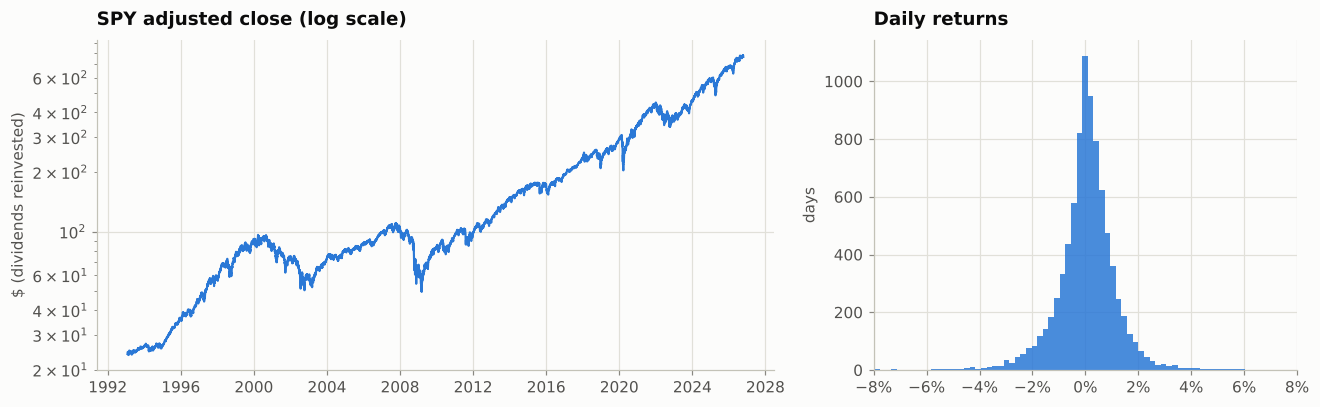

In [4]:
ret = px["close"].pct_change().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(px.index, px["close"], color=P.CATEGORICAL[0], lw=1.4)
ax.set_yscale("log"); ax.set_title("SPY adjusted close (log scale)")
ax.set_ylabel("$ (dividends reinvested)")
ax = axes[1]
ax.hist(ret, bins=120, color=P.CATEGORICAL[0], alpha=0.85)
ax.set_title("Daily returns"); P.pct(ax, "x", 0)
ax.set_xlim(-0.08, 0.08); ax.set_ylabel("days")
fig.tight_layout(); P.save(fig, "01_price_and_returns")
print(f"Daily return: mean {ret.mean():.3%}, std {ret.std():.3%}; "
      f"5-day std about {ret.std()*np.sqrt(5):.2%}; worst day {ret.min():.1%}, best day {ret.max():.1%}")

## 3. The 14 input features

Each feature is **one number per day**, computed at that day's close from that day and earlier. Windows are the standard published defaults, fixed up front (not tuned).

In [5]:
feats = build_features(px)
info = pd.DataFrame(FEATURE_INFO, index=["name", "calculated as", "looks back"]).T
info

,name,calculated as,looks back
ret_1d,Return 1d,Close / close 1 day ago - 1,1 day
ret_5d,Return 5d,Close / close 5 days ago - 1,1 week
ret_10d,Return 10d,Close / close 10 days ago - 1,2 weeks
ret_20d,Return 20d,Close / close 20 days ago - 1,1 month
close_sma20,Close / SMA20,Close / average of last 20 closes,1 month
close_sma50,Close / SMA50,Close / average of last 50 closes,~2.5 months
sma50_sma200,SMA50 / SMA200,50-day average / 200-day average,~10 months
rsi_14,RSI(14),"Wilder RSI, 0-100",3 weeks
macd_hist,MACD histogram / price,(EMA12 - EMA26 - signal EMA9) / close,~1.5 months
bb_pctb,Bollinger %B,"(close - lower) / (upper - lower), SMA20 +/- 2 SD",1 month


In [6]:
first_full = feats.dropna().index[0]
print("First row with all 14 features:", first_full.date(), "(SMA200 needs 200 trading days of history)")
feats.dropna().describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

First row with all 14 features: 1993-11-11 (SMA200 needs 200 trading days of history)


,mean,std,min,25%,50%,75%,max
ret_1d,0.0005,0.0118,-0.1094,-0.0044,0.0007,0.0060,0.1452
ret_5d,0.0023,0.0239,-0.1979,-0.0093,0.0038,0.0152,0.1940
ret_10d,0.0046,0.0321,-0.2677,-0.0106,0.0073,0.0224,0.2158
ret_20d,0.0092,0.0446,-0.3099,-0.0133,0.0144,0.0348,0.2362
close_sma20,1.0040,0.0252,0.7875,0.9923,1.0076,1.0188,1.1145
close_sma50,1.0104,0.0390,0.7260,0.9930,1.0166,1.0351,1.1435
sma50_sma200,1.0314,0.0587,0.7539,1.0067,1.0408,1.0703,1.1526
rsi_14,55.1143,11.3433,16.8027,47.0008,56.0507,63.5954,87.1909
macd_hist,-0.0000,0.0035,-0.0315,-0.0018,0.0000,0.0018,0.0214
bb_pctb,0.5919,0.3239,-0.4731,0.3439,0.6725,0.8515,1.3228


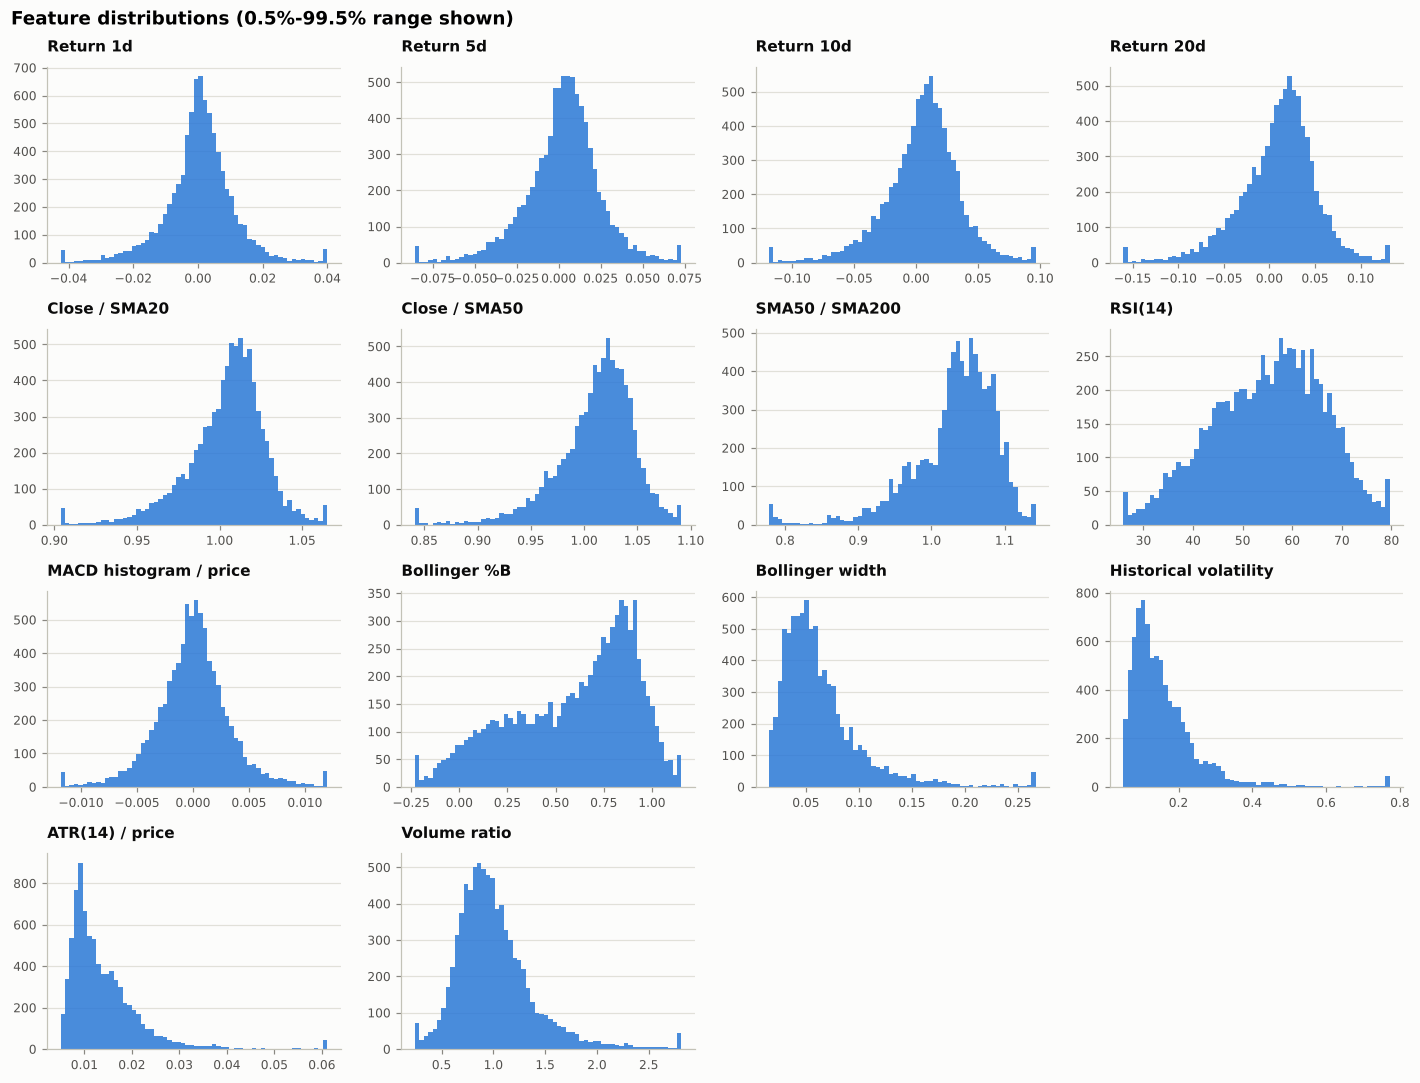

In [7]:
F = feats.dropna()
fig, axes = plt.subplots(4, 4, figsize=(13, 10))
for ax, col in zip(axes.flat, FEATURES):
    lo, hi = F[col].quantile([0.005, 0.995])
    ax.hist(F[col].clip(lo, hi), bins=60, color=P.CATEGORICAL[0], alpha=0.85)
    ax.set_title(FEATURE_INFO[col][0], fontsize=10)
    ax.tick_params(labelsize=8); ax.grid(axis="x", visible=False)
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Feature distributions (0.5%-99.5% range shown)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); P.save(fig, "01_feature_distributions")

### Indicator correlations

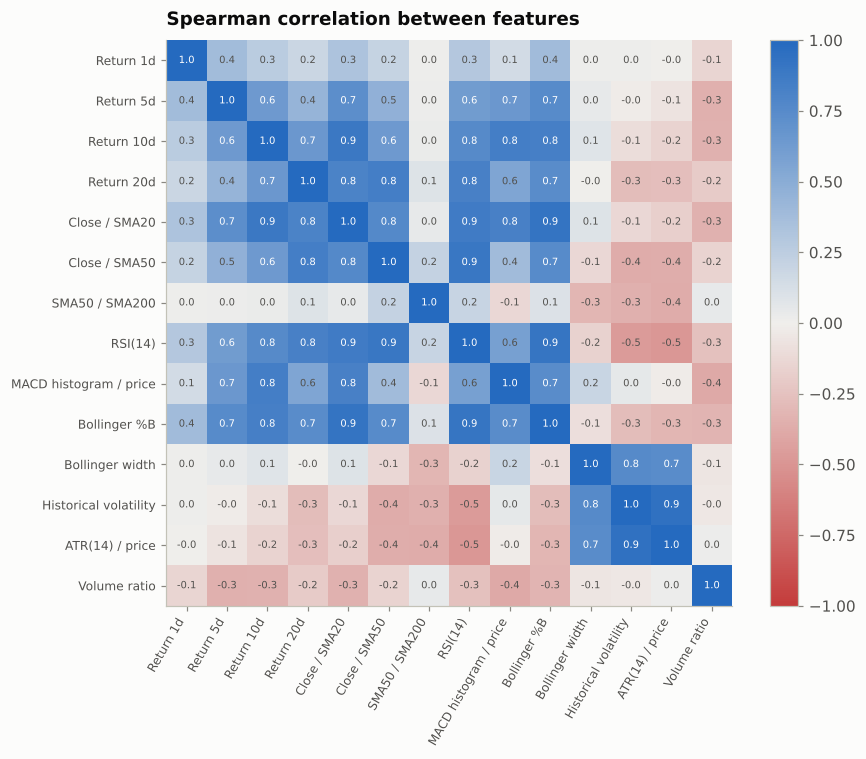

In [8]:
corr = F.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=P.DIVERGING, vmin=-1, vmax=1)
names = [FEATURE_INFO[c][0] for c in FEATURES]
ax.set_xticks(range(len(FEATURES)), names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)), names, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else P.INK2)
ax.grid(False); ax.set_title("Spearman correlation between features")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout(); P.save(fig, "01_feature_correlations")

In [9]:
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().rename("spearman").reset_index()
         .assign(abs=lambda d: d.spearman.abs()).sort_values("abs", ascending=False))
pairs[pairs["abs"] >= 0.8].drop(columns="abs")

,level_0,level_1,spearman
166,vol_20d,atr_14,0.9393
65,close_sma20,bb_pctb,0.9172
107,rsi_14,bb_pctb,0.9082
77,close_sma50,rsi_14,0.8936
32,ret_10d,close_sma20,0.8867
63,close_sma20,rsi_14,0.8644
47,ret_20d,close_sma50,0.8433
36,ret_10d,macd_hist,0.8395
37,ret_10d,bb_pctb,0.8300
64,close_sma20,macd_hist,0.8243


## 4. The target: Buy / Hold / Sell

In [10]:
fwd = forward_return(px["close"])
y = make_labels(px["close"])
data = feats.join(y).dropna()
print(f"Modelling rows: {len(data):,} from {data.index[0].date()} to {data.index[-1].date()}")
share = data["label"].map(CLASS_NAMES).value_counts(normalize=True).reindex(["Buy", "Hold", "Sell"])
share.to_frame("share of days")

Modelling rows: 8,283 from 1993-11-11 to 2026-10-09


,share of days
label,
Buy,0.3570
Hold,0.4040
Sell,0.2390


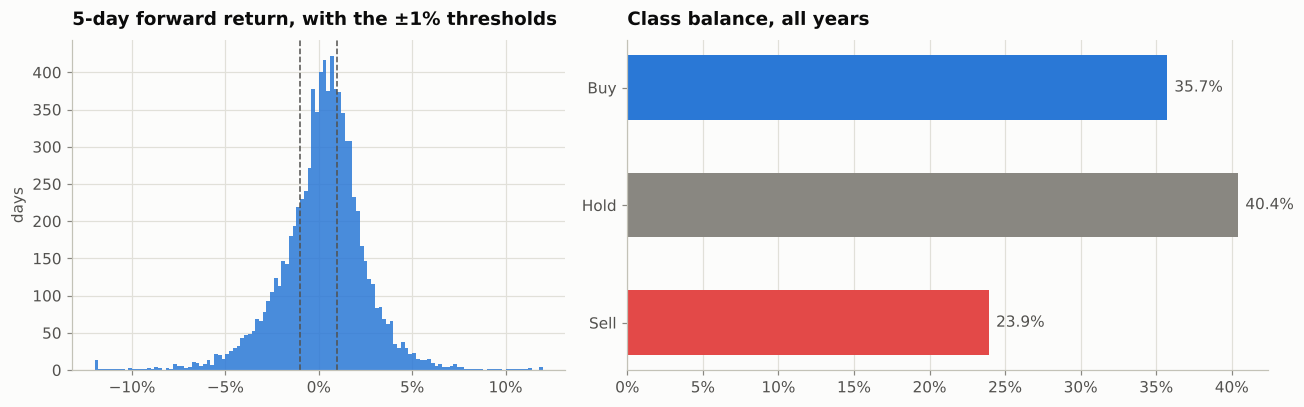

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
f5 = fwd.dropna()
ax.hist(f5.clip(-0.12, 0.12), bins=120, color=P.CATEGORICAL[0], alpha=0.85)
for t in (-THRESHOLD, THRESHOLD):
    ax.axvline(t, color=P.INK2, lw=1, ls="--")
ax.set_title("5-day forward return, with the ±1% thresholds"); P.pct(ax, "x", 0); ax.set_ylabel("days")
ax = axes[1]
ax.barh(["Sell", "Hold", "Buy"], share.reindex(["Sell", "Hold", "Buy"]), color=[P.CLASS_COLORS[c] for c in ["Sell", "Hold", "Buy"]], height=0.55)
for i, c in enumerate(["Sell", "Hold", "Buy"]):
    ax.text(share[c] + 0.005, i, f"{share[c]:.1%}", va="center", color=P.INK2)
ax.set_title("Class balance, all years"); P.pct(ax, "x", 0); ax.grid(axis="y", visible=False)
fig.tight_layout(); P.save(fig, "01_target")

### Class balance per year

The ±1% band is fixed, but the market's typical 5-day move is not. In calm years most weeks fall inside ±1% (Hold), and in crises few do. The agreed rule: keep ±1% unless the per-year shares swing badly (a class below about 15% in most years). If they do, switch to a volatility-scaled band.

cls,Sell,Hold,Buy
Date,,,
1993,9%,77%,14%
1994,21%,55%,24%
1995,6%,58%,35%
1996,24%,35%,41%
1997,25%,32%,43%
1998,24%,25%,50%
1999,31%,29%,40%
2000,37%,31%,32%
2001,36%,28%,36%


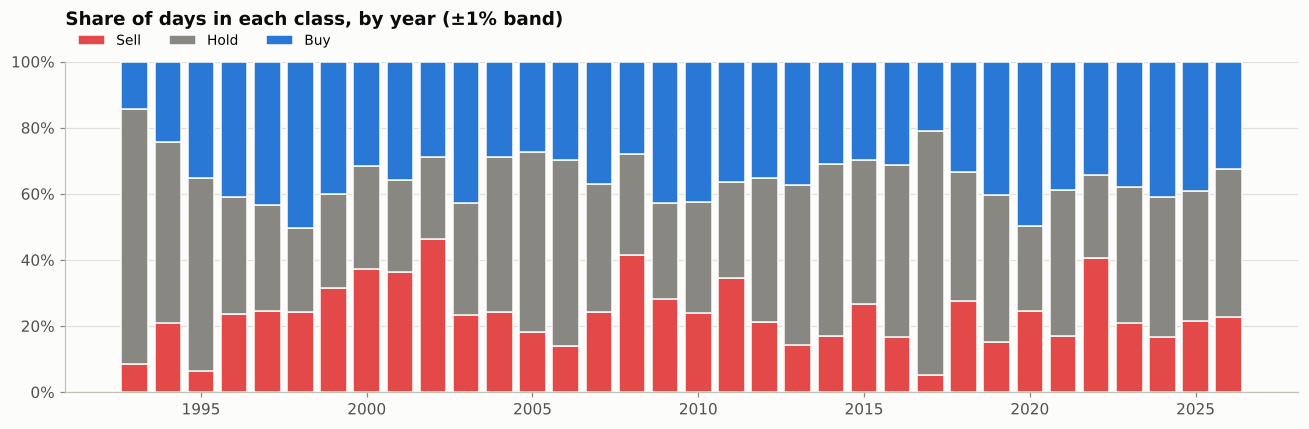

In [12]:
by_year = (data.assign(cls=data["label"].map(CLASS_NAMES)).groupby(data.index.year)["cls"]
           .value_counts(normalize=True).unstack().reindex(columns=["Sell", "Hold", "Buy"]).fillna(0))
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(by_year))
for c in ["Sell", "Hold", "Buy"]:
    ax.bar(by_year.index, by_year[c], bottom=bottom, color=P.CLASS_COLORS[c], width=0.8, label=c, edgecolor=P.SURFACE, linewidth=1)
    bottom += by_year[c].values
ax.set_ylim(0, 1); P.pct(ax); ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.12))
ax.set_title("Share of days in each class, by year (±1% band)", pad=24)
fig.tight_layout(); P.save(fig, "01_class_by_year")
by_year.style.format("{:.0%}").background_gradient(cmap=P.SEQUENTIAL, vmin=0, vmax=0.8)

In [13]:
low = (by_year < 0.15)
summary = pd.DataFrame({
    "years with a class below 15%": [int(low.any(axis=1).sum())],
    "of years": [len(by_year)],
    "Sell below 15%": [int(low["Sell"].sum())], "Hold below 15%": [int(low["Hold"].sum())], "Buy below 15%": [int(low["Buy"].sum())],
})
summary

,years with a class below 15%,of years,Sell below 15%,Hold below 15%,Buy below 15%
0,5,34,5,0,1


### Alternative checked: volatility-scaled band

Band = 0.4 × 20-day volatility × √5, which widens in wild markets and narrows in calm ones. It is shown here only for comparison with the fixed band.

In [14]:
thr_v = vol_scaled_threshold(px["close"])
y_v = make_labels(px["close"], threshold=thr_v)
dv = y_v.dropna()
dv = dv[dv.index >= data.index[0]]
by_year_v = (dv.map(CLASS_NAMES).groupby(dv.index.year).value_counts(normalize=True).unstack()
             .reindex(columns=["Sell", "Hold", "Buy"]).fillna(0))
comp = pd.DataFrame({
    "fixed ±1%: min class share in year (median over years)": [by_year.min(axis=1).median()],
    "fixed ±1%: years with a class < 15%": [int((by_year < 0.15).any(axis=1).sum())],
    "vol-scaled: min class share in year (median)": [by_year_v.min(axis=1).median()],
    "vol-scaled: years with a class < 15%": [int((by_year_v < 0.15).any(axis=1).sum())],
}).T.rename(columns={0: "value"})
comp

,value
fixed ±1%: min class share in year (median over years),0.2352
fixed ±1%: years with a class < 15%,5.0000
vol-scaled: min class share in year (median),0.2555
vol-scaled: years with a class < 15%,2.0000


### Decision: keep the fixed ±1% band

- **Overall balance:** Buy 35.7%, Hold 40.4%, Sell 23.9%. The classes are unequal, but none is tiny.
- **Years with a class below 15%:** 5 of 34. They are 1993 (a partial year), 1995, 2006, 2013 and 2017. All were calm, rising years where Sell weeks were rare (5–14%). Hold never falls below 15%, and Buy does so only in partial-year 1993.
- **Rule applied:** the agreed rule was to switch only if a class falls below about 15% in *most* years. Five of 34 is far from most, so **±1% stays**.
- **Volatility-scaled band:** it would cut the count to 2 years. But it changes what "Buy" means from year to year and is harder to explain, so it isn't needed.
- **Imbalance:** the remaining imbalance (Sell 24%) is handled in notebook 02 with class weights or oversampling of training folds.

## 5. How the features differ by class

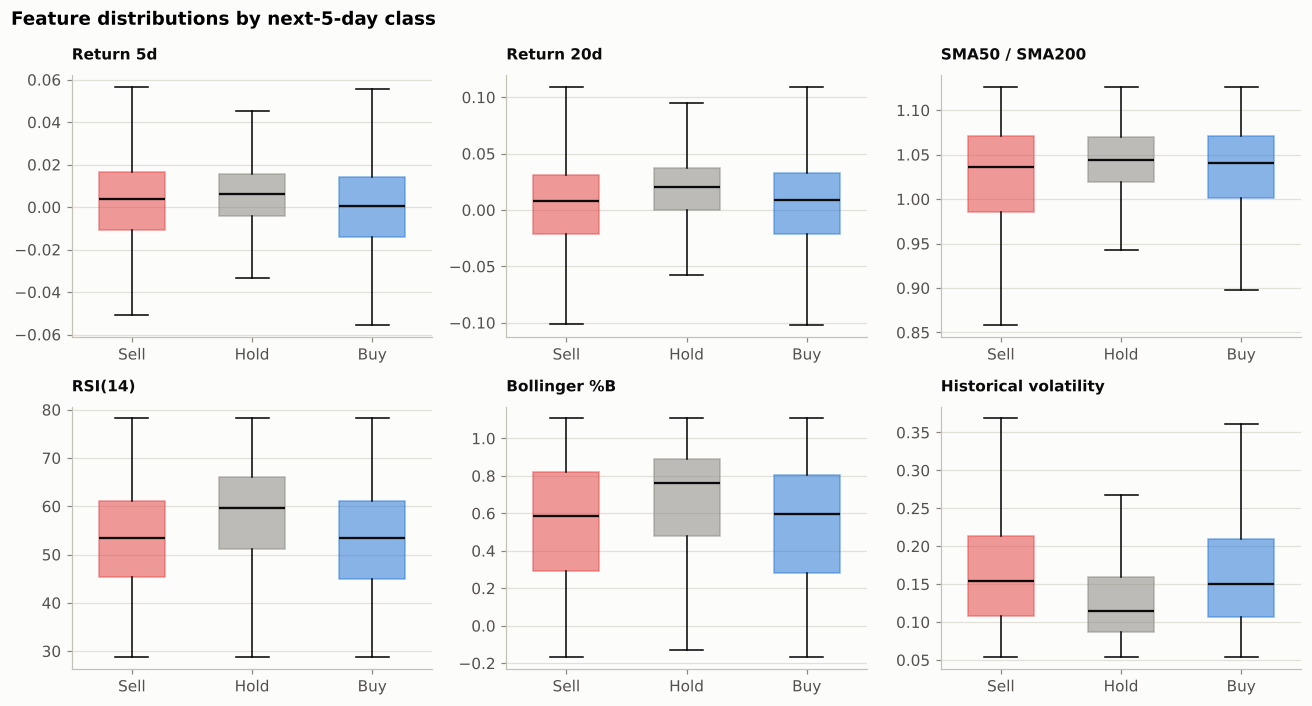

In [15]:
show = ["ret_5d", "ret_20d", "sma50_sma200", "rsi_14", "bb_pctb", "vol_20d"]
d = data.assign(cls=data["label"].map(CLASS_NAMES))
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.flat, show):
    groups = [d.loc[d.cls == c, col].clip(*d[col].quantile([0.01, 0.99])) for c in ["Sell", "Hold", "Buy"]]
    bp = ax.boxplot(groups, tick_labels=["Sell", "Hold", "Buy"], showfliers=False, patch_artist=True, widths=0.55,
                    medianprops=dict(color=P.INK, lw=1.5))
    for patch, c in zip(bp["boxes"], ["Sell", "Hold", "Buy"]):
        patch.set_facecolor(P.CLASS_COLORS[c]); patch.set_alpha(0.55); patch.set_edgecolor(P.CLASS_COLORS[c])
    ax.set_title(FEATURE_INFO[col][0], fontsize=10); ax.grid(axis="x", visible=False)
fig.suptitle("Feature distributions by next-5-day class", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); P.save(fig, "01_features_by_class")

In [16]:
means = d.groupby("cls")[FEATURES].median().reindex(["Sell", "Hold", "Buy"]).T
means.index = [FEATURE_INFO[c][0] for c in means.index]
means

cls,Sell,Hold,Buy
Return 1d,0.0006,0.0011,0.0003
Return 5d,0.0038,0.0061,0.0004
Return 10d,0.0033,0.0118,0.0036
Return 20d,0.0078,0.0204,0.0093
Close / SMA20,1.0043,1.0115,1.0045
Close / SMA50,1.0106,1.0224,1.0109
SMA50 / SMA200,1.0364,1.0437,1.0402
RSI(14),53.3386,59.5780,53.4082
MACD histogram / price,-0.0002,0.0004,-0.0003
Bollinger %B,0.5861,0.7609,0.5939


In [17]:
# Volatility clustering: Sell AND Buy weeks are both more common when volatility is high
q = pd.qcut(d["vol_20d"], 5, labels=["lowest", "low", "middle", "high", "highest"])
vol_tab = pd.crosstab(q, d["cls"], normalize="index").reindex(columns=["Sell", "Hold", "Buy"])
vol_tab.index.name = "20-day volatility quintile"
vol_tab.style.format("{:.0%}")

cls,Sell,Hold,Buy
20-day volatility quintile,,,
lowest,16%,58%,26%
low,20%,49%,31%
middle,24%,40%,36%
high,28%,32%,40%
highest,32%,23%,45%


## EDA findings that shape the modelling

1. **Returns are noisy and fat-tailed.** The average day is +0.05%, against a typical swing of ±1.17%. The 5-day standard deviation is about 2.6%, so a ±1% band is about 0.4 of a typical week's move. The worst day was −10.9% and the best +14.5%.
2. **Many indicators measure the same thing.** Twelve feature pairs have |Spearman| ≥ 0.8. The strongest are volatility vs ATR (0.94), Close/SMA20 vs Bollinger %B (0.92) and RSI vs %B (0.91). All 14 are kept: tree models are not harmed by overlap, and logistic regression can drop features through its L1 setting. The overlap is noted when reading permutation importance, because correlated features share credit.
3. **Hold days look different; Buy and Sell days look alike.** Hold weeks follow calm markets: lower volatility (median 11% vs about 15%), narrower bands, and higher RSI and %B. Buy and Sell weeks start from almost identical conditions (median RSI 53.4 vs 53.3, volatility 15.0% vs 15.4%).
4. **Volatility predicts the size of the next move, not its direction.** In the calmest fifth of days, 58% of weeks are Hold. In the wildest fifth, only 23% are Hold, and both Buy (45%) and Sell (32%) rise.
5. **What to expect from the models:** they should find "calm vs wild" fairly easily, but telling Buy from Sell is the hard part. Always guessing Hold would score about 40% accuracy on a macro-F1 of only about 0.19, which is why macro-F1, not accuracy, is the main metric.